# 05. Validation and baselines

**Where we are:** notebook 04 fixed the information cut-off (08:30 UTC on the day before) and
built the weather and live-demand tables.

**What this notebook does:**

1. Builds the validation harness: how every model from here on is scored before the test window.
2. Scores simple baselines that use only past demand and the calendar.
3. Compares them with NESO.

**Why baselines first:** a machine-learning model is only worth its complexity if it beats
simple rules. Baselines also catch bugs: if a fancy model loses to "same time last week",
something is wrong.

**Environment:** from here the notebooks run in a project `.venv` built on top of the conda
environment (`python -m venv --system-site-packages .venv`), adding LightGBM for Day 6. See
`requirements.txt`.

**Background reading**
- [Forecasting: Principles and Practice, section 5.2, simple forecasting methods](https://otexts.com/fpp3/simple-methods.html)
- [Forecasting: Principles and Practice, section 5.10, time series cross-validation](https://otexts.com/fpp3/tscv.html)


## Step 1. Set up and load


In [1]:
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROCESSED = Path("../data/processed")
TEST_START = pd.Timestamp("2024-06-01", tz="Europe/London")

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 90,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e4e0",
    "lines.linewidth": 2,
})

demand = pd.read_parquet(PROCESSED / "demand.parquet")
indo = pd.read_parquet(PROCESSED / "indo.parquet")
bench = pd.read_parquet(PROCESSED / "neso_benchmark.parquet")
bank_holidays = pd.to_datetime(list(holidays.UK(subdiv="ENG", years=range(2018, 2027))))

ORIGIN_TIME = pd.Timedelta(hours=8, minutes=30)


def forecast_origin(target_date):
    """08:30 UTC on the day before the local target date (notebook 04)."""
    return (pd.Timestamp(target_date) - pd.Timedelta(days=1) + ORIGIN_TIME).tz_localize("UTC")


## Step 2. Rolling-origin validation

**What:** split the two years before the test window into 24 monthly folds, June 2022 to May
2024. For each fold, a model may learn only from days that were complete before that month's
first forecast was made, then forecasts every day of the month.

**Why not a random split:** demand on Tuesday is close to demand on Monday. A random split puts
neighbouring days on both sides, so the model is scored on days it has nearly seen. Rolling
forward in time copies how the forecast is used for real: always predicting the future from the past.

**Why monthly folds over two years:** every season appears twice, and the model is refitted as
often as a real system might be retrained. Two years also covers the drift found in notebook 03.

**The training cut-off:** the first forecast of a fold is made at 08:30 UTC on the day before the
fold starts. The last complete day at that moment is two days before the fold starts, so training
targets stop there.


In [2]:
def make_folds(first="2022-06-01", last="2024-05-01"):
    folds = []
    for start in pd.date_range(first, last, freq="MS"):
        end = start + pd.offsets.MonthEnd(0)
        folds.append({"fold": f"{start:%Y-%m}", "train_until": start - pd.Timedelta(days=2),
                      "start": start, "end": end})
    return pd.DataFrame(folds)


FOLDS = make_folds()
assert (FOLDS["end"] < TEST_START.tz_localize(None)).all(), "a fold reaches into the test window"
print(len(FOLDS), "folds")
FOLDS.head(3)


24 folds


,fold,train_until,start,end
0,2022-06,2022-05-30,2022-06-01,2022-06-30
1,2022-07,2022-06-29,2022-07-01,2022-07-31
2,2022-08,2022-07-30,2022-08-01,2022-08-31


**The scoring function:** every model is a function that takes one fold and returns a
forecast for each half-hour in it. The harness runs it over all folds and scores the result
against NESO's `Demand_Outturn` (notebook 02 chose this target for scoring), on exactly the
half-hours where NESO also has a forecast. So the comparison with NESO is always like for like.


In [3]:
targets = bench[["start_utc", "Date", "Settlement_Period", "Demand_Forecast", "Demand_Outturn"]].copy()
targets["date"] = pd.to_datetime(targets["Date"])
targets["local"] = targets["start_utc"].dt.tz_convert("Europe/London").dt.tz_localize(None)


def run_folds(forecaster, folds=FOLDS):
    """Forecast every half-hour of every fold; forecaster(fold, rows) returns one value per row."""
    parts = []
    for fold in folds.itertuples():
        rows = targets[targets["date"].between(fold.start, fold.end)].copy()
        rows["forecast"] = forecaster(fold, rows)
        rows["fold"] = fold.fold
        parts.append(rows)
    return pd.concat(parts, ignore_index=True)


def scores(forecast, actual):
    error = forecast - actual
    return pd.Series({"MAE": error.abs().mean(), "RMSE": np.sqrt((error ** 2).mean()),
                      "MAPE": (error.abs() / actual).mean() * 100, "bias": error.mean()})


def neso_forecaster(fold, rows):
    return rows["Demand_Forecast"].to_numpy()


neso = run_folds(neso_forecaster)
print(f"{len(neso):,} half-hours in validation, {neso['Date'].min()} to {neso['Date'].max()}")
scores(neso["forecast"], neso["Demand_Outturn"]).round(1)


35,038 half-hours in validation, 2022-06-01 to 2024-05-31


MAE     605.3
RMSE    807.7
MAPE      2.3
bias     34.1
dtype: float64

**Found:** over the 24 validation months (35,038 half-hours, June 2022 to May 2024), NESO scores
MAE 605 MW and MAPE 2.3%, with a small upward bias (+34 MW). That is lower than its 689 MW on the
test window (notebook 02), which fits the rising errors found there: the test window is the harder period.


## Step 3. Looking up past demand by local clock time

**What:** a helper that returns live demand (`INDO`) at the same local clock time a given number
of days earlier.

**Why local time:** "same time last week" should mean 17:30 on the wall clock, because people's
routines follow the wall clock. Shifting UTC by seven days is an hour out in the week after each
clock change (noted in notebook 03).

**Clock-change gaps:** in spring the local hour from 01:00 to 02:00 does not exist, and in
autumn it happens twice. A lookup into a spring change day finds nothing for that hour, so those
gaps are filled from the neighbouring half-hour. In autumn the first of the two repeated hours is kept.


In [4]:
def local_naive(utc):
    return utc.dt.tz_convert("Europe/London").dt.tz_localize(None)


indo_by_local = (indo.assign(local=local_naive(indo["start_utc"]))
                 .drop_duplicates("local").set_index("local")["INDO"].sort_index())


def demand_days_before(rows, days):
    """INDO at the same local clock time `days` days before each row (array of days allowed)."""
    keys = rows["local"] - pd.to_timedelta(np.broadcast_to(days, len(rows)), unit="D")
    values = indo_by_local.reindex(keys.to_numpy())
    return pd.Series(values.to_numpy(), index=rows.index).ffill().bfill().to_numpy()


## Step 4. Three simple baselines

| Baseline | Forecast for each half-hour | Uses the morning of D−1? |
|---|---|---|
| **Last week** | demand at the same local time 7 days earlier | no |
| **Four-week mean** | mean of the same time 7, 14, 21 and 28 days earlier | no |
| **Last week, rescaled** | last week, times the ratio of the latest 24 hours of demand to the same 24 hours a week before | yes |

**Why the rescaled version:** notebook 03 found that a week-old value has the right shape but
can be at the wrong level, for example when a cold spell starts. The latest 24 hours that are
known at the origin (08:00 UTC on D−2 to 08:00 UTC on D−1) show whether demand this week is
running above or below last week.

**Checking the cut-off:** the ratio uses only `INDO` periods that end by 08:00 UTC on D−1, the
rule from notebook 04. The assert below checks that for every target day.


In [5]:
def last_week(fold, rows):
    return demand_days_before(rows, 7)


def four_week_mean(fold, rows):
    return np.mean([demand_days_before(rows, d) for d in (7, 14, 21, 28)], axis=0)


indo_by_utc = indo.set_index("start_utc")["INDO"].sort_index()


def level_ratio(target_date):
    """Latest 24 hours of INDO known at the origin, divided by the same 24 hours a week earlier."""
    last_start = forecast_origin(target_date) - pd.Timedelta(hours=1)  # period ending 08:00 UTC
    window = pd.date_range(end=last_start, periods=48, freq="30min")
    assert window[-1] + pd.Timedelta(minutes=30) <= forecast_origin(target_date) - pd.Timedelta(minutes=30)
    recent = indo_by_utc.reindex(window).mean()
    earlier = indo_by_utc.reindex(window - pd.Timedelta(days=7)).mean()
    return recent / earlier


def last_week_rescaled(fold, rows):
    ratios = rows["Date"].map({d: level_ratio(d) for d in rows["Date"].unique()})
    return demand_days_before(rows, 7) * ratios.to_numpy()


results = {"NESO": neso}
for name, forecaster in [("last week", last_week), ("four-week mean", four_week_mean),
                         ("last week, rescaled", last_week_rescaled)]:
    results[name] = run_folds(forecaster)

pd.DataFrame({name: scores(r["forecast"], r["Demand_Outturn"]) for name, r in results.items()}).T.round(1)


,MAE,RMSE,MAPE,bias
NESO,605.3,807.7,2.3,34.1
last week,2033.1,2732.1,7.8,10.9
four-week mean,2123.2,2871.3,8.0,20.1
"last week, rescaled",1911.5,2534.6,7.4,62.0


**Found:**

- All three baselines are about three times worse than NESO: MAE 1,900 to 2,100 MW against 605 MW.
- **Four-week mean is worse than last week** (2,123 against 2,033 MW). Averaging older weeks
  smooths noise but drags in an older level of demand, and notebook 03 showed the level moves.
- **Rescaling by the latest 24 hours helps:** 1,912 MW, 6% better than plain last week. So the
  live demand from the morning before (notebook 04) carries useful information, as hoped.
- A sanity check on the size: notebook 03 found a correlation of 0.91 between demand and demand
  a week earlier. With half-hourly demand varying by about 5.5 GW, that implies a typical miss of
  about 2 GW, which is what we see. The harness is working.


## Step 5. A similar-day baseline that knows about holidays

**What:** pick a better reference day than "seven days ago":

- If the target day is a bank holiday, use the most recent Sunday that is complete at the
  origin (notebook 03 found holidays look like weekends).
- Otherwise use the same weekday a week earlier, or two weeks earlier if last week's day was a
  bank holiday.

Then rescale by the latest 24 hours, as in Step 4.

**Why:** the simple baselines copy last week blindly, so a bank holiday Monday gets a normal
Monday's forecast, and the Monday after gets a holiday's. This is the cheapest fix and shows how
much of the baseline error is just the calendar.


In [6]:
holiday_set = set(bank_holidays)


def reference_days_back(target_date):
    target = pd.Timestamp(target_date)
    if target in holiday_set:
        back = 2
        while (target - pd.Timedelta(days=back)).dayofweek != 6:
            back += 1
        return back
    return 14 if (target - pd.Timedelta(days=7)) in holiday_set else 7


def similar_day(fold, rows):
    back = rows["Date"].map({d: reference_days_back(d) for d in rows["Date"].unique()}).to_numpy()
    ratios = rows["Date"].map({d: level_ratio(d) for d in rows["Date"].unique()}).to_numpy()
    return demand_days_before(rows, back) * ratios


results["similar day"] = run_folds(similar_day)
table = pd.DataFrame({name: scores(r["forecast"], r["Demand_Outturn"]) for name, r in results.items()}).T
table.round(1)


,MAE,RMSE,MAPE,bias
NESO,605.3,807.7,2.3,34.1
last week,2033.1,2732.1,7.8,10.9
four-week mean,2123.2,2871.3,8.0,20.1
"last week, rescaled",1911.5,2534.6,7.4,62.0
similar day,1875.8,2498.4,7.3,40.7


**Found:** the similar-day baseline is the best of the four at MAE 1,876 MW (MAPE 7.3%), but only
36 MW better than the rescaled baseline. Bank holidays are a small share of all half-hours, so
fixing them barely moves the overall score; Step 7 shows the effect on the days themselves.


## Step 6. Where do the baselines lose to NESO?

**What:** MAE by month for NESO and the best baseline, and by local time of day.

**Why:** an overall score hides where the errors come from. If the baseline loses everywhere,
the calendar and recent demand are not enough. If it loses mostly at midday in sunny months,
that is the weather gap the model on Day 6 should close.


best baseline: similar day


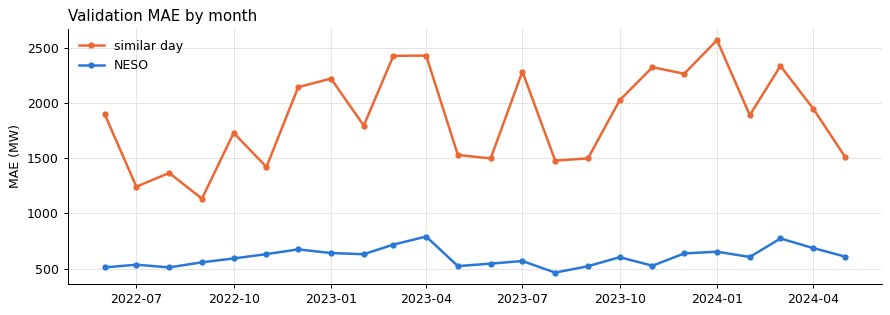

fold,2022-06,2022-07,2022-08,2022-09,2022-10,2022-11,2022-12,2023-01,2023-02,2023-03,...,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05
NESO,512.0,536.0,512.0,558.0,593.0,632.0,675.0,642.0,631.0,718.0,...,465.0,523.0,604.0,527.0,638.0,654.0,606.0,774.0,687.0,610.0
similar day,1900.0,1243.0,1367.0,1134.0,1730.0,1421.0,2144.0,2222.0,1796.0,2427.0,...,1479.0,1499.0,2026.0,2325.0,2265.0,2570.0,1890.0,2336.0,1949.0,1515.0


In [7]:
best = table.drop(index="NESO")["MAE"].idxmin()
print("best baseline:", best)

monthly = pd.DataFrame({
    name: results[name].groupby("fold").apply(lambda g: (g["forecast"] - g["Demand_Outturn"]).abs().mean(),
                                              include_groups=False)
    for name in ["NESO", best]
})

fig, ax = plt.subplots(figsize=(10, 3.6))
for name, color in [(best, ORANGE), ("NESO", BLUE)]:
    ax.plot(pd.to_datetime(monthly.index), monthly[name], color=color, label=name, marker="o", markersize=4)
ax.set_ylabel("MAE (MW)")
ax.set_title("Validation MAE by month", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()
monthly.round(0).T


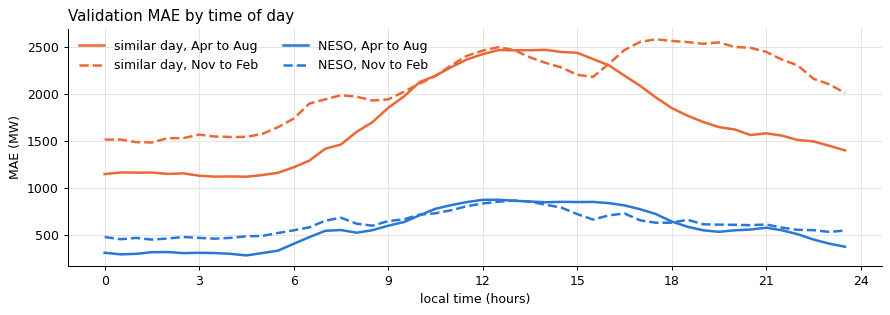

In [8]:
def by_time_of_day(frame):
    hour = frame["local"].dt.hour + frame["local"].dt.minute / 60
    return (frame["forecast"] - frame["Demand_Outturn"]).abs().groupby(hour).mean()


fig, ax = plt.subplots(figsize=(10, 3.6))
for name, color in [(best, ORANGE), ("NESO", BLUE)]:
    for months, style, label in [([4, 5, 6, 7, 8], "-", "Apr to Aug"), ([11, 12, 1, 2], "--", "Nov to Feb")]:
        frame = results[name][results[name]["date"].dt.month.isin(months)]
        mae = by_time_of_day(frame)
        ax.plot(mae.index, mae.values, color=color, linestyle=style, label=f"{name}, {label}")
ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("local time (hours)")
ax.set_ylabel("MAE (MW)")
ax.set_title("Validation MAE by time of day", loc="left")
ax.legend(frameon=False, ncol=2)
fig.tight_layout()
plt.show()


**Found:**

- The best baseline loses to NESO in every month, by about 580 MW at best (September 2022) and by
  about 1,900 MW at worst (January 2024).
- **Most of the baseline's worst months are in winter and early spring** (2,100 to 2,600 MW in
  December 2022 to January 2023, March and April 2023, November 2023 to January 2024 and March
  2024): a week-old value cannot know that this week is colder. July 2023 was also bad (2,280 MW).
- **By time of day**, the baseline's error peaks around 2,500 MW at midday in spring and summer,
  and in the late afternoon and evening in winter. NESO's error is flatter, between about 300
  and 900 MW.
- So the gap is not only at midday. The baseline lacks the weather everywhere: temperature in
  winter evenings, sunshine in summer middays.

**What this means for Day 6:** the calendar and recent demand alone leave the forecast about
three times worse than NESO. The weather forecasts from notebook 04 are the main thing to add.


## Step 7. Christmas and bank holidays

**What:** score the period from 20 December to 7 January, and bank holidays, separately.

**Why:** notebook 03 found these days behave unlike anything else. A model can look good
overall and still fail badly on them, and they matter to the people using the forecast.


In [9]:
def special(frame):
    day = frame["date"]
    christmas = ((day.dt.month == 12) & (day.dt.day >= 20)) | ((day.dt.month == 1) & (day.dt.day <= 7))
    return pd.Series(np.where(christmas, "Christmas period", np.where(day.isin(bank_holidays), "bank holiday", "normal days")),
                     index=frame.index)


rows = []
for name in ["NESO", "last week, rescaled", "similar day"]:
    frame = results[name]
    for group, part in frame.groupby(special(frame)):
        rows.append({"model": name, "days": group,
                     "MAE": (part["forecast"] - part["Demand_Outturn"]).abs().mean(), "half-hours": len(part)})
pd.DataFrame(rows).pivot(index="days", columns="model", values="MAE").round(0)


model,NESO,"last week, rescaled",similar day
days,,,
Christmas period,732.0,2492.0,2670.0
bank holiday,737.0,2898.0,1387.0
normal days,595.0,1859.0,1841.0


**Found:**

- **Bank holidays:** the similar-day rule more than halves the baseline's error on bank holidays
  (2,898 to 1,387 MW). That is the calendar effect from notebook 03, in MW.
- **Christmas period:** both baselines are at 2,500 to 2,700 MW, against NESO's 732 MW. Copying
  last week is useless when last week was a normal working week. Day 6 needs the Christmas
  feature from notebook 03.
- NESO is only about 140 MW worse on these days than on normal days, so they handle the calendar well.


## Step 8. Save the validation forecasts

**What:** keep every model's validation forecasts in one file, so later notebooks compare against
exactly the same rows.


In [10]:
saved = pd.concat([r[["start_utc", "fold", "forecast", "Demand_Outturn"]].assign(model=name)
                   for name, r in results.items()], ignore_index=True)
saved.to_parquet(PROCESSED / "validation_forecasts.parquet", index=False)
saved.groupby("model").size()


model
NESO                   35038
four-week mean         35038
last week              35038
last week, rescaled    35038
similar day            35038
dtype: int64

## Summary and next step

**The harness:** 24 monthly rolling-origin folds from June 2022 to May 2024. Each model is a
function of the fold; the harness trains only on days complete before the fold's first origin,
and scores against NESO's outturn on the same 35,038 half-hours as NESO.

**Validation scores**

| Model | MAE (MW) | MAPE |
|---|---|---|
| NESO | 605 | 2.3% |
| Similar day (holiday-aware, rescaled) | 1,876 | 7.3% |
| Last week, rescaled | 1,912 | 7.4% |
| Last week | 2,033 | 7.8% |
| Four-week mean | 2,123 | 8.0% |

**What I learnt**
- Simple rules are three times worse than NESO. That is the scale of what the weather, the
  calendar and the daily shape together have to make up.
- The latest live demand helps a little; handling holidays helps a lot on those days and very
  little overall.
- The baseline's errors are largest in winter and in the daytime, which is where temperature and
  sunshine matter.

**Next (Day 6):** a LightGBM model with calendar, lag and weather features, run through the same
harness, trained on actual weather and validated on actual weather for 2022 to early 2024, and
checked on forecast weather from March 2024.
